# Lesson 2 · Walking through the fly olfactory circuit in the data

Goal: count the neurons at every layer of the circuit and see its **convergence → expansion → convergence** shape with your own eyes.

```
odor → ORN (~1,100/side) → glomerulus (~50) → uPN (~2.5/glomerulus) → KC (~2,600) → MBON (~50)
                                                    ↘ LH (innate behaviour)        ↑ DAN (learning signal)
                                                                   APL ⟲ KC (global inhibition)
```

- **ORN** (olfactory receptor neuron): each expresses one receptor type; all ORNs with the same receptor converge on one **glomerulus**.
- **uPN** (uniglomerular projection neuron): takes the signal of one glomerulus to the **mushroom body calyx** and the **lateral horn (LH)**.
- **KC** (Kenyon cell): each samples a few glomeruli; together they form a large, sparse odour code.
- **MBON** (mushroom body output neuron): reads out the KCs and drives behaviour.
- **DAN** (dopaminergic neuron): signals reward or punishment and changes KC→MBON synapses, which is where learning happens.
- **APL**: one inhibitory neuron per side that keeps KC activity sparse.

We count only the **right** side, so the numbers at each layer are directly comparable. Run from top to bottom with **Shift + Enter**.

## Step 0: load the data (provided)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ann = pd.read_csv("../data/neuron_annotations.tsv", sep="\t", low_memory=False)
right = ann[ann.side == "right"]   # every filter below starts from `right`
print(len(right), "neurons on the right side")

69088 neurons on the right side


## TODO 1: ORNs (olfactory receptor neurons)

- ORNs have `cell_class == "olfactory"`.
- Their `cell_type` looks like `"ORN_DA1"`: the part after the underscore is the **glomerulus** they project to.

To do:
1. Keep the ORNs from `right` as `orns` and print how many there are;
2. add a column `glom`: `orns["glom"] = orns.cell_type.str.replace("ORN_", "")`;
3. count the ORNs per glomerulus with `orns.glom.value_counts()`, then call `.describe()` on the result.

`.describe()` gives count, mean, min, max and so on; here the count is the number of glomeruli.

In [2]:
# TODO 1
orns = right[right.cell_class == "olfactory"].copy()
print(len(orns), "ORNs on the right side")
orns["glom"] = orns.cell_type.str.replace("ORN_", "")
orns_per_glom = orns.glom.value_counts()
print(orns_per_glom.head(10))
orns_per_glom.describe()

1134 ORNs on the right side
glom
DA1     66
VA1d    45
DL3     42
VM4     40
VL1     39
VL2a    38
VA1v    38
DL1     34
DM1     33
V       33
Name: count, dtype: int64


count    53.000000
mean     21.358491
std      11.758948
min       5.000000
25%      13.000000
50%      17.000000
75%      28.000000
max      66.000000
Name: count, dtype: float64

## TODO 2: uniglomerular PNs (uPNs)

- uPNs have `cell_class == "ALPN"` **and** `cell_sub_class == "uniglomerular"`. Both conditions must hold: write `(condition1) & (condition2)`, each in parentheses.
- Their `cell_type` looks like `"DA1_lPN"`; take the part **before** the underscore: `.str.split("_").str[0]`.

To do:
1. Keep the uPNs as `upns` and print how many there are;
2. add a `glom` column;
3. print the number of glomeruli (`.nunique()`) and a summary of uPNs per glomerulus (`.value_counts().describe()`).

Think: each glomerulus receives about 20 ORNs but sends out only about 2.5 uPNs. Is this step convergence or expansion?

In [3]:
# TODO 2
upns = right[(right.cell_class == "ALPN") & (right.cell_sub_class == "uniglomerular")].copy()
print(len(upns), "uniglomerular PNs on the right side")
upns["glom"] = upns.cell_type.str.split("_").str[0]
print(upns.glom.nunique(), "glomeruli")
upns.glom.value_counts().describe()
# ~20 ORNs -> ~2.5 uPNs per glomerulus: this step is convergence.

139 uniglomerular PNs on the right side
56 glomeruli


count    56.000000
mean      2.482143
std       1.694816
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       8.000000
Name: count, dtype: float64

## TODO 3: Kenyon cells (KCs)

There are three main KC classes, recognisable by the `cell_type` prefix: `KCg…` is γ, `KCab…` is αβ, `KCapbp…` is α'β'.

To do:
1. Keep the right-side KCs (`cell_class == "Kenyon_Cell"`) as `kcs` and print how many there are;
2. print `kcs.cell_type.value_counts()`.

Bonus: count each of the three classes, e.g. `kcs.cell_type.str.startswith("KCg").sum()`. Careful: `"KCab"` is not a prefix of `"KCapbp"`, but `"KCa"` would match both.

In [4]:
# TODO 3
kcs = right[right.cell_class == "Kenyon_Cell"].copy()
print(len(kcs), "KCs on the right side")
print(kcs.cell_type.value_counts())

for prefix in ["KCg", "KCab", "KCapbp"]:
    print(prefix, kcs.cell_type.str.startswith(prefix).sum())

2597 KCs on the right side
cell_type
KCg-m         1120
KCab           799
KCapbp-m       174
KCapbp-ap2     160
KCg-d          148
KCapbp-ap1     132
KCab-p          61
KCa'b'-ap1       1
KCg-s1           1
KCg-s2           1
Name: count, dtype: int64
KCg 1270
KCab 860
KCapbp 466


## TODO 4: MBONs, DANs and APL

- MBON (mushroom body output neuron): `cell_class == "MBON"`
- DAN (dopaminergic neuron): `cell_class == "DAN"`
- APL: `cell_type == "APL"`

To do: count each of them on the right side.

Bonus: DANs fall into two clusters, PAM and PPL, which roughly signal reward and punishment. Have a look with `cell_type.str[:3].value_counts()`.

In [5]:
# TODO 4
mbons = right[right.cell_class == "MBON"]
dans = right[right.cell_class == "DAN"]
apls = right[right.cell_type == "APL"]
print(len(mbons), "MBONs |", len(dans), "DANs |", len(apls), "APL")
dans.cell_type.str[:3].value_counts()

48 MBONs | 165 DANs | 1 APL


cell_type
PAM    153
PPL     12
Name: count, dtype: int64

## TODO 5: plot the "shape" of the circuit

Put the count of each layer in a dict and draw a bar chart. Use a log scale on the y axis, since the layers differ by about 1000×.

```python
counts = {"ORN": ..., "glomerulus": ..., "uPN": ..., "KC": ..., "MBON": ...}
plt.bar(counts.keys(), counts.values())
plt.yscale("log")
plt.ylabel("neurons (right side)")
plt.show()
```

Then compute three ratios:
- **ORN / glomerulus**: how many ORNs converge on each glomerulus (convergence);
- **KC / glomerulus**: from ~50 input channels to how many dimensions (the **expansion ratio**);
- **KC / MBON**: how strongly the readout compresses again (convergence).

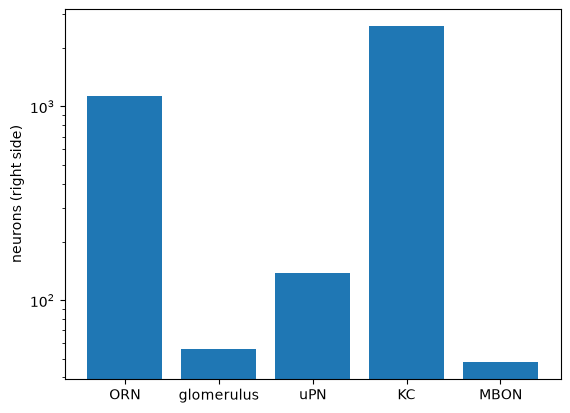

ORN / glomerulus = 21.4
KC / glomerulus (expansion ratio) = 46.4
KC / MBON = 54.1


In [6]:
# TODO 5
counts = {"ORN": len(orns), "glomerulus": upns.glom.nunique(), "uPN": len(upns),
          "KC": len(kcs), "MBON": len(mbons)}
plt.bar(counts.keys(), counts.values())
plt.yscale("log")
plt.ylabel("neurons (right side)")
plt.show()

print(f"ORN / glomerulus = {len(orns) / orns.glom.nunique():.1f}")
print(f"KC / glomerulus (expansion ratio) = {len(kcs) / upns.glom.nunique():.1f}")
print(f"KC / MBON = {len(kcs) / len(mbons):.1f}")

## Self-test

1. In one sentence, describe the path of an odour from ORN to MBON, with one English keyword for what each layer does (e.g. *convergence*, *expansion*, *sparsening*, *readout*).
2. Why would the system first **expand** ~50 dimensions to ~2,600 and then **compress** them back to ~50? Guess from intuition; Lesson 5 answers this properly.
3. If APL were removed, what would KC activity look like? What would that do to the discrimination of two similar odours?
4. What role do DANs play in this circuit? Why are they key to learning?

**Model answers:**

1. ORNs detect odorants, converge by receptor type onto glomeruli (*convergence*), uPNs relay each channel (*relay*), KCs mix a few channels each and only the most active ~5% fire (*expansion* + *sparsening*), and MBONs sum the KC activity (*readout*).
2. In a high-dimensional, sparse code, different odours activate largely non-overlapping sets of KCs, so a simple (linear) readout can learn an arbitrary good/bad label for many odours. The compression afterwards is just that readout: few behavioural outputs.
3. Many more KCs would be active, and the sets activated by similar odours would overlap much more. The two odours would become harder to tell apart, and learning about one would generalise to the other.
4. DANs carry the reward/punishment signal. Dopamine changes the KC→MBON synapses of the KCs that are active at that moment, so it ties "this odour" to "this outcome": it is the teaching signal.